# ORIE 5530 Project, Part II: Simulation

Simulates the six Markov chains of Part I: W 21 St, Ave A and 7 Ave & CPS, weekday mornings (7-10am) and evenings (4-7pm), with a 5 minute step.

The transition matrices are read from `outputs/matrices/`, where `part1_markov_chains.ipynb` saves them, so sections 1 to 4 do not need the trip data. Section 5 checks the recommendation against the rides themselves and reads `data/trips_clean.parquet`, like Part I. Run all cells from top to bottom. Every result uses the seed and the number of runs set in the first cell, and the cells can be run in any order after the first four.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11})
plt.rcParams["font.family"] = "Inter"

SEED = 5530            # random seed for every reported result
N_RUNS = 10_000        # simulation runs per case
STEPS_PER_BLOCK = 36   # 5 minute steps in a 3 hour block
STEP_MINUTES = 5

In [2]:
# same stations, docks and colors as Part I, keyed by the name used in the matrix files
STATIONS = {
    "W21St": {"name": "W 21 St", "docks": 74, "color": "#2a78d6"},
    "AveA": {"name": "Ave A", "docks": 41, "color": "#eb6834"},
    "7AveCPS": {"name": "7 Ave & CPS", "docks": 81, "color": "#1baf7a"},
}
BLOCKS = {"Morning": (7, 10), "Evening": (16, 19)}

P_all = {}
for key, st in STATIONS.items():
    for block in BLOCKS:
        P = pd.read_csv(f"outputs/matrices/P_{key}_{block}.csv", index_col=0).to_numpy()
        # one row and column per number of bikes, and every row is a probability distribution
        assert P.shape == (st["docks"] + 1, st["docks"] + 1) and np.allclose(P.sum(axis=1), 1)
        P_all[(key, block)] = P
print(len(P_all), "matrices loaded")

6 matrices loaded


## 1. Simulating one chain

A run starts from a chosen number of bikes. At each of the 36 steps we draw the next state from the row of the transition matrix for the current state. We draw it with the inverse transform method: take a uniform random number `u` and pick the first state whose cumulative probability is above `u`.

The quantity we estimate is the **unavailable minutes**: the minutes of a block during which the station is empty (no bike to take) or full (no dock to return one). We look at the station at the 36 five minute marks after the start and count 5 minutes for each mark where it is at 0 or at its number of docks.

In [3]:
def simulate(key, block, start, n_runs=N_RUNS):
    # Returns one row per run and one column per 5 minute mark, from the start (column 0) to the end of the block (column 36).
    # Each case gets its own random stream built from the seed, the station, the block and the starting state,
    # so a case gives the same result wherever it is run in the notebook.
    rng = np.random.default_rng([SEED, list(STATIONS).index(key), list(BLOCKS).index(block), start])
    P = P_all[(key, block)]
    cum = np.cumsum(P, axis=1)   # cumulative probabilities of every row
    cum[:, -1] = 1.0             # protects against rounding in the last column
    paths = np.empty((n_runs, STEPS_PER_BLOCK + 1), dtype=int)
    paths[:, 0] = start
    for n in range(STEPS_PER_BLOCK):
        u = rng.random(n_runs)   # one uniform number per run
        # next state = number of states whose cumulative probability is below u
        paths[:, n + 1] = (cum[paths[:, n]] < u[:, None]).sum(axis=1)
    return paths

def unavailable_minutes(paths, C):
    # minutes with the station empty or full, counted at the 36 marks after the start
    at_edge = (paths[:, 1:] == 0) | (paths[:, 1:] == C)
    return at_edge.sum(axis=1) * STEP_MINUTES

def exact_unavailable_minutes(P, start):
    # the same average computed from the matrix without simulating, used to check the simulation
    # P is one matrix for the whole block, or a list with one matrix per step
    matrices = P if isinstance(P, list) else [P] * STEPS_PER_BLOCK
    C = len(matrices[0]) - 1
    dist = np.zeros(C + 1)
    dist[start] = 1.0
    total = 0.0
    for M in matrices:
        dist = dist @ M
        total += dist[0] + dist[C]
    return total * STEP_MINUTES

def ci_half_width(x):
    # half width of the 95% confidence interval of a mean, from the central limit theorem
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))

## 2. Runs for each station and block (report Part II, section 1)

Every chain starts half full, as in Part I: 37 bikes at W 21 St, 20 at Ave A and 40 at 7 Ave & CPS.

In [4]:
runs = {}
rows = []
for (key, block), P in P_all.items():
    C = STATIONS[key]["docks"]
    start = C // 2
    paths = simulate(key, block, start)
    runs[(key, block)] = paths
    minutes = unavailable_minutes(paths, C)
    rows.append({
        "station": STATIONS[key]["name"], "block": block, "start": start,
        "avg bikes at end": paths[:, -1].mean(),
        "avg unavailable minutes": minutes.mean(),
        "95% CI +/-": ci_half_width(minutes),
        "exact": exact_unavailable_minutes(P, start),
        "share of runs unavailable at least once": (minutes > 0).mean(),
        "worst 10% of runs, at least (min)": np.percentile(minutes, 90),
    })
table_runs = pd.DataFrame(rows)
table_runs.round(3)

,station,block,start,avg bikes at end,avg unavailable minutes,95% CI +/-,exact,share of runs unavailable at least once,"worst 10% of runs, at least (min)"
0,W 21 St,Morning,37,70.348,19.116,0.338,19.062,0.752,45.0
1,W 21 St,Evening,37,8.030,10.516,0.250,10.314,0.573,30.0
2,Ave A,Morning,20,6.223,12.990,0.350,12.848,0.503,40.0
3,Ave A,Evening,20,33.257,11.280,0.281,11.388,0.553,30.0
4,7 Ave & CPS,Morning,40,59.094,1.302,0.104,1.286,0.086,0.0
5,7 Ave & CPS,Evening,40,19.250,4.244,0.182,4.250,0.254,15.0


In [5]:
# the simulated average must agree with the exact value from the matrix, up to simulation noise
gap = (table_runs["avg unavailable minutes"] - table_runs["exact"]).abs()
assert (gap < 2 * table_runs["95% CI +/-"] + 0.05).all()
print("largest gap between simulation and exact value:", round(gap.max(), 2), "minutes")

largest gap between simulation and exact value: 0.2 minutes


In [6]:
# how much the starting state matters: empty, half full, full, and the start with the fewest unavailable minutes
rows = []
for (key, block), P in P_all.items():
    C = STATIONS[key]["docks"]
    best = int(np.argmin([exact_unavailable_minutes(P, s) for s in range(C + 1)]))
    row = {"station": STATIONS[key]["name"], "block": block}
    for label, start in [("start empty", 0), ("start half full", C // 2), ("start full", C), ("best start", best)]:
        row[label] = unavailable_minutes(simulate(key, block, start), C).mean()
    row["best start (bikes)"] = best
    rows.append(row)
table_starts = pd.DataFrame(rows)
table_starts.round(1)

,station,block,start empty,start half full,start full,best start,best start (bikes)
0,W 21 St,Morning,3.2,19.1,64.1,1.7,5
1,W 21 St,Evening,39.6,10.5,4.8,1.7,64
2,Ave A,Morning,58.2,13.0,8.7,2.5,34
3,Ave A,Evening,9.1,11.3,36.9,5.1,8
4,7 Ave & CPS,Morning,9.1,1.3,44.0,0.1,21
5,7 Ave & CPS,Evening,35.1,4.2,8.3,1.1,60


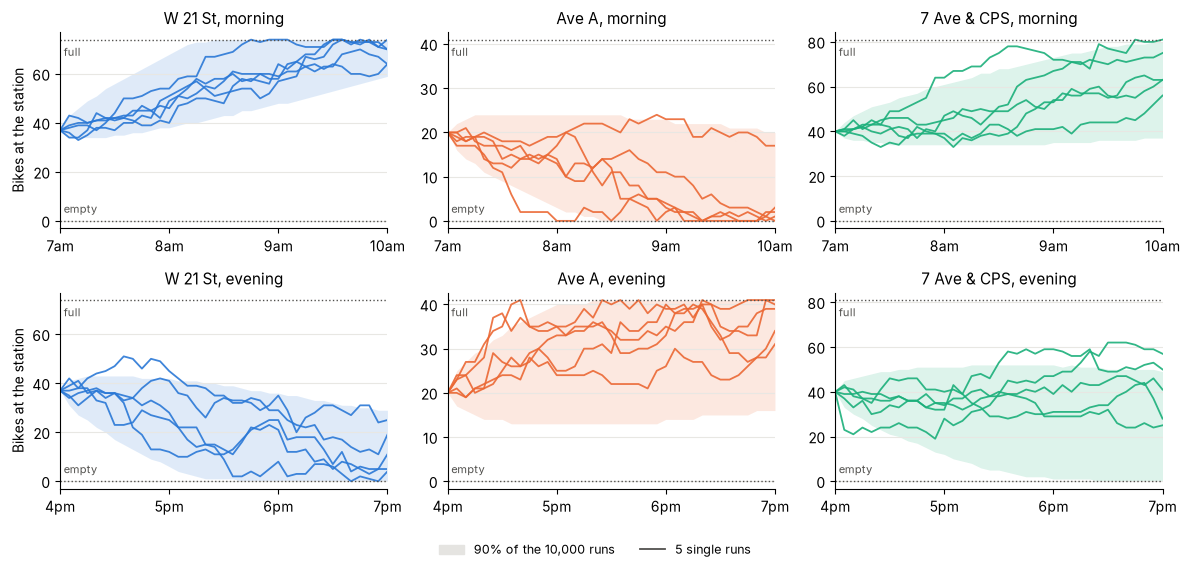

In [7]:
# Figure 7: a few runs for each station and block, with the range covered by 90% of all runs
N_SHOWN = 5
minutes_axis = np.arange(STEPS_PER_BLOCK + 1) * STEP_MINUTES
fig, axes = plt.subplots(2, 3, figsize=(12, 5.7))
for c, (key, st) in enumerate(STATIONS.items()):
    C = st["docks"]
    for r, (block, (start_h, end_h)) in enumerate(BLOCKS.items()):
        paths = runs[(key, block)]
        ax = axes[r, c]
        low, high = np.percentile(paths, [5, 95], axis=0)
        ax.fill_between(minutes_axis, low, high, color=st["color"], alpha=0.15, lw=0)
        for i in range(N_SHOWN):
            ax.plot(minutes_axis, paths[i], color=st["color"], lw=1.3, alpha=0.9)
        for level in (0, C):
            ax.axhline(level, color="#52514e", lw=1, ls=":")
        ax.text(2, C - 0.03 * C, "full", va="top", fontsize=8, color="#52514e")
        ax.text(2, 0.03 * C, "empty", va="bottom", fontsize=8, color="#52514e")
        ax.set_title(f"{st['name']}, {block.lower()}")
        ax.set_xlim(0, 180)
        ax.set_ylim(-0.04 * C, 1.04 * C)
        ax.set_xticks(range(0, 181, 60))
        ax.set_xticklabels([f"{(h - 1) % 12 + 1}{'am' if h < 12 else 'pm'}" for h in range(start_h, end_h + 1)])
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e8e7e3")
for ax in axes[:, 0]:
    ax.set_ylabel("Bikes at the station")
fig.tight_layout(rect=(0, 0.06, 1, 1))
legend_items = [Patch(color="#e5e4e1", label=f"90% of the {N_RUNS:,} runs"),
                Line2D([], [], color="#52514e", lw=1.3, label=f"{N_SHOWN} single runs")]
fig.legend(handles=legend_items, frameon=False, fontsize=9, loc="lower center", ncol=2)
fig.savefig("figures/p2_sample_paths.png", dpi=250, bbox_inches="tight")

## 3. Recommendation: moving bikes between W 21 St and Ave A (report Part II, section 2)

In the morning W 21 St fills up while Ave A runs out of bikes, and in the evening it is the opposite. We test moving `k` bikes from the station that is about to gain bikes to the one that is about to lose them, just before the block starts: from W 21 St to Ave A before the morning block and from Ave A to W 21 St before the evening block. The only thing that changes in the simulation is the starting state of the two stations.

In [8]:
MOVES = range(0, 19)
DIRECTION = {"Morning": ("W21St", "AveA"), "Evening": ("AveA", "W21St")}   # (from, to)

rows = []
for block, (src, dst) in DIRECTION.items():
    for k in MOVES:
        row = {"block": block, "bikes moved": k}
        both = np.zeros(N_RUNS)
        for key, change in [(src, -k), (dst, +k)]:
            C = STATIONS[key]["docks"]
            start = C // 2 + change
            minutes = unavailable_minutes(simulate(key, block, start), C)
            row[STATIONS[key]["name"]] = minutes.mean()
            row[STATIONS[key]["name"] + ", exact"] = exact_unavailable_minutes(P_all[(key, block)], start)
            both += minutes   # the two stations are simulated independently
        row["Both stations"] = both.mean()
        row["95% CI +/-"] = ci_half_width(both)
        rows.append(row)
sweep = pd.DataFrame(rows)
sweep["Both stations, exact"] = sweep["W 21 St, exact"] + sweep["Ave A, exact"]
assert ((sweep["Both stations"] - sweep["Both stations, exact"]).abs() < 2 * sweep["95% CI +/-"] + 0.05).all()

In [9]:
# with and without the change: no move, the 5 bikes of the project example, and our recommendation of 15
RECOMMENDED = 15
compare = sweep[sweep["bikes moved"].isin([0, 5, RECOMMENDED])].copy()
no_move = compare.groupby("block")["Both stations"].transform("first")
compare["change vs no move"] = compare["Both stations"] / no_move - 1
compare[["block", "bikes moved", "W 21 St", "Ave A", "Both stations", "95% CI +/-", "change vs no move"]].round(3)

,block,bikes moved,W 21 St,Ave A,Both stations,95% CI +/-,change vs no move
0,Morning,0,19.116,12.990,32.106,0.485,0.000
5,Morning,5,14.044,6.753,20.797,0.396,-0.352
15,Morning,15,6.637,2.802,9.439,0.262,-0.706
19,Evening,0,10.516,11.280,21.796,0.377,0.000
24,Evening,5,7.657,7.332,14.990,0.309,-0.312
34,Evening,15,3.730,5.352,9.082,0.229,-0.583


In [10]:
# number of bikes with the fewest unavailable minutes in each block
best = sweep.loc[sweep.groupby("block")["Both stations"].idxmin(), ["block", "bikes moved", "Both stations"]]
best.round(2)

,block,bikes moved,Both stations
34,Evening,15,9.08
16,Morning,16,9.18


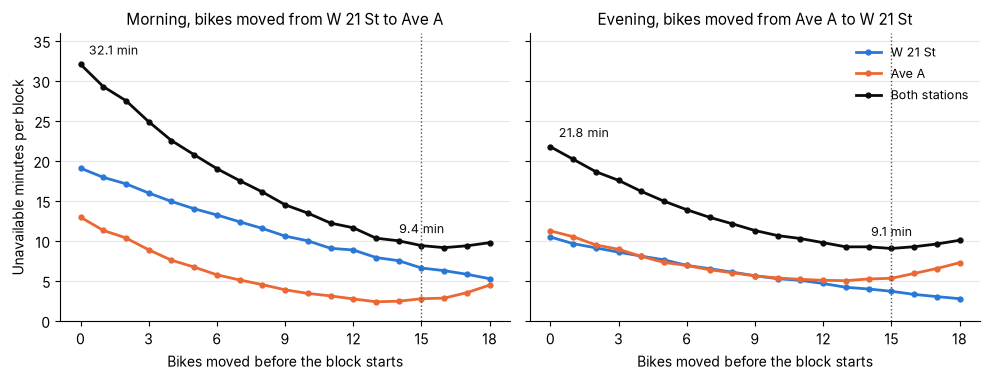

In [11]:
# Figure 8: unavailable minutes against the number of bikes moved
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
titles = {"Morning": "Morning, bikes moved from W 21 St to Ave A", "Evening": "Evening, bikes moved from Ave A to W 21 St"}
for ax, block in zip(axes, BLOCKS):
    d = sweep[sweep.block == block]
    for key in ("W21St", "AveA"):
        st = STATIONS[key]
        ax.plot(d["bikes moved"], d[st["name"]], color=st["color"], lw=2, marker="o", ms=3.5, label=st["name"])
    ax.plot(d["bikes moved"], d["Both stations"], color="#0b0b0b", lw=2, marker="o", ms=3.5, label="Both stations")
    for k in (0, RECOMMENDED):
        y = d.loc[d["bikes moved"] == k, "Both stations"].iloc[0]
        ax.annotate(f"{y:.1f} min", (k, y), textcoords="offset points", xytext=(6, 7) if k == 0 else (0, 9),
                    ha="left" if k == 0 else "center", fontsize=9, color="#0b0b0b")
    ax.axvline(RECOMMENDED, color="#52514e", lw=1, ls=":")
    ax.set_title(titles[block])
    ax.set_xlabel("Bikes moved before the block starts")
    ax.set_xticks(range(0, 19, 3))
    ax.set_ylim(0, 36)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e8e7e3")
axes[0].set_ylabel("Unavailable minutes per block")
axes[1].legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig("figures/p2_recommendation.png", dpi=250, bbox_inches="tight")

## 4. When the move does not help

Two cases where moving bikes makes things worse:

- the bikes moved in the morning are not moved back, so the evening block starts with W 21 St short of bikes and Ave A nearly full,
- the two stations already start the morning well stocked for it, and 5 more bikes are moved anyway.

In [12]:
def both_stations(block, start_w21, start_avea):
    # average unavailable minutes of the two stations together, for given starting states
    total = np.zeros(N_RUNS)
    for key, start in [("W21St", start_w21), ("AveA", start_avea)]:
        total += unavailable_minutes(simulate(key, block, start), STATIONS[key]["docks"])
    return total.mean(), ci_half_width(total)

cases = [
    ("Evening, half full (no move)", "Evening", 37, 20),
    ("Evening, morning move of 15 left in place", "Evening", 37 - RECOMMENDED, 20 + RECOMMENDED),
    ("Morning, already well stocked (20 and 35)", "Morning", 20, 35),
    ("Morning, well stocked and 5 more moved", "Morning", 15, 40),
]
rows = []
for label, block, w, a in cases:
    mean, half = both_stations(block, w, a)
    rows.append({"case": label, "W 21 St start": w, "Ave A start": a, "Both stations": mean, "95% CI +/-": half})
pd.DataFrame(rows).round(2)

,case,W 21 St start,Ave A start,Both stations,95% CI +/-
0,"Evening, half full (no move)",37,20,21.80,0.38
1,"Evening, morning move of 15 left in place",22,35,51.39,0.48
2,"Morning, already well stocked (20 and 35)",20,35,8.66,0.25
3,"Morning, well stocked and 5 more moved",15,40,10.86,0.26


## 5. Checks of the recommendation with the trip data (report Part II, section 2)

The confidence intervals above only measure the randomness of the simulation. Here we check the recommendation against the rides themselves, in three ways:

- **Real days replayed:** replay the rides of each of the 21 weekdays in order from the same starting states, with no Markov chain.
- **One matrix per hour:** Part I showed that the flow changes within a block, so we repeat the calculation with a separate matrix for each hour.
- **Resampled days:** the matrices rest on 21 days, so we draw 21 days with replacement 500 times, rebuild the matrices each time and see how much the result moves.

The last two use the exact value from the matrices, which section 2 showed agrees with the simulation.

In [13]:
# rides of the two commuter stations turned into events, exactly as in part1_markov_chains.ipynb
STATION_IDS = {"W21St": "6140.05", "AveA": "5779.11"}
cols = ["started_at", "ended_at", "start_station_id", "end_station_id"]
trips = pd.read_parquet("data/trips_clean.parquet", columns=cols)
departures = pd.DataFrame({"station": trips.start_station_id, "time": trips.started_at, "event": -1})
arrivals = pd.DataFrame({"station": trips.end_station_id, "time": trips.ended_at, "event": 1})
events = pd.concat([departures, arrivals], ignore_index=True).dropna(subset=["station"])
events["station"] = events.station.astype(str).str.rstrip("_")
events = events[events.station.isin(list(STATION_IDS.values()))]
events = events[(events.time.dt.month == 8) & (events.time.dt.dayofweek < 5)].sort_values("time", kind="stable")
weekdays = pd.date_range("2026-08-01", "2026-08-31")
weekdays = weekdays[weekdays.dayofweek < 5]

def day_sequences(key, block):
    # result[d][n] is the list of events of step n on weekday d, in time order
    start_h, end_h = BLOCKS[block]
    e = events[(events.station == STATION_IDS[key]) & (events.time.dt.hour >= start_h) & (events.time.dt.hour < end_h)]
    by_step = e.groupby(e.time.dt.floor("5min")).event.apply(list)
    return [[by_step.get(day + pd.Timedelta(hours=start_h, minutes=STEP_MINUTES * n), []) for n in range(STEPS_PER_BLOCK)]
            for day in weekdays]

def step_counts(days, C):
    # counts[d, h, i, j] = number of steps of day d and hour h that take the station from i to j bikes (replay rule)
    counts = np.zeros((len(days), 3, C + 1, C + 1))
    start = np.arange(C + 1)
    for d, day in enumerate(days):
        for n, seq in enumerate(day):
            bikes = start.copy()
            for e in seq:
                bikes = np.clip(bikes + e, 0, C)
            counts[d, n // 12, start, bikes] += 1
    return counts

def to_matrix(counts):
    # turn counts of steps into transition probabilities
    return counts / counts.sum(axis=1, keepdims=True)

sequences, counts = {}, {}
for key in STATION_IDS:
    for block in BLOCKS:
        sequences[(key, block)] = day_sequences(key, block)
        counts[(key, block)] = step_counts(sequences[(key, block)], STATIONS[key]["docks"])
        # the matrix rebuilt from the rides must be the one Part I saved
        assert np.allclose(to_matrix(counts[(key, block)].sum(axis=(0, 1))), P_all[(key, block)])
print(len(weekdays), "weekdays, matrices rebuilt from the rides match outputs/matrices")

21 weekdays, matrices rebuilt from the rides match outputs/matrices


In [14]:
def starts(block, k):
    # starting states of the two stations when k bikes are moved before the block
    src, dst = DIRECTION[block]
    return {src: STATIONS[src]["docks"] // 2 - k, dst: STATIONS[dst]["docks"] // 2 + k}

def replay_day(day, start, C):
    # replay the real events of one day in order and count its unavailable minutes
    bikes, minutes = start, 0
    for seq in day:
        for e in seq:
            bikes = min(max(bikes + e, 0), C)
        minutes += STEP_MINUTES * (bikes == 0 or bikes == C)
    return minutes

def both_exact(matrices, block, k):
    # exact unavailable minutes of the two stations together, matrices[key] is one matrix or a list of 36
    return sum(exact_unavailable_minutes(matrices[key], start) for key, start in starts(block, k).items())

N_RESAMPLES = 500
rng = np.random.default_rng(SEED)
rows = []
for block in BLOCKS:
    # simulation, from section 3
    d = sweep[sweep.block == block].set_index("bikes moved")["Both stations"]
    rows.append({"block": block, "check": "Simulation", "no move": d[0], "move 15": d[RECOMMENDED]})

    # 21 real days replayed
    real = {k: sum(np.array([replay_day(day, start, STATIONS[key]["docks"]) for day in sequences[(key, block)]])
                   for key, start in starts(block, k).items()) for k in (0, RECOMMENDED)}
    rows.append({"block": block, "check": "21 real days replayed", "no move": real[0].mean(), "move 15": real[RECOMMENDED].mean(),
                 "days better": str(int((real[RECOMMENDED] < real[0]).sum())), "days worse": str(int((real[RECOMMENDED] > real[0]).sum()))})

    # one matrix per hour
    hourly = {key: [to_matrix(counts[(key, block)][:, n // 12].sum(axis=0)) for n in range(STEPS_PER_BLOCK)] for key in STATION_IDS}
    rows.append({"block": block, "check": "One matrix per hour",
                 "no move": both_exact(hourly, block, 0), "move 15": both_exact(hourly, block, RECOMMENDED)})

    # resampled days: 90% range over the resamples
    res = []
    for _ in range(N_RESAMPLES):
        pick = rng.integers(0, len(weekdays), len(weekdays))
        resampled = {key: to_matrix(counts[(key, block)][pick].sum(axis=(0, 1))) for key in STATION_IDS}
        a, b = both_exact(resampled, block, 0), both_exact(resampled, block, RECOMMENDED)
        res.append((a, b, b / a - 1))
    low, high = np.percentile(np.array(res), [5, 95], axis=0)
    rows.append({"block": block, "check": f"Resampled days, 90% range of {N_RESAMPLES}",
                 "no move": f"{low[0]:.1f} to {high[0]:.1f}", "move 15": f"{low[1]:.1f} to {high[1]:.1f}",
                 "change": f"{low[2]:+.0%} to {high[2]:+.0%}", "resamples where the move helps": f"{np.mean(np.array(res)[:, 2] < 0):.0%}"})
checks = pd.DataFrame(rows)
is_number = checks["change"].isna()
checks.loc[is_number, "change"] = [f"{b / a - 1:+.0%}" for a, b in zip(checks.loc[is_number, "no move"], checks.loc[is_number, "move 15"])]
for col in ("no move", "move 15"):
    checks[col] = [f"{v:.1f}" if not isinstance(v, str) else v for v in checks[col]]
checks.fillna("")

,block,check,no move,move 15,days better,days worse,change,resamples where the move helps
0,Morning,Simulation,32.1,9.4,,,-71%,
1,Morning,21 real days replayed,32.9,11.4,17,0,-65%,
2,Morning,One matrix per hour,30.7,9.4,,,-69%,
3,Morning,"Resampled days, 90% range of 500",26.8 to 37.1,7.5 to 12.1,,,-74% to -65%,100%
4,Evening,Simulation,21.8,9.1,,,-58%,
5,Evening,21 real days replayed,18.8,5.5,15,1,-71%,
6,Evening,One matrix per hour,19.5,9.2,,,-52%,
7,Evening,"Resampled days, 90% range of 500",18.0 to 26.0,7.8 to 11.0,,,-61% to -52%,100%
